# Boundary compression vs baseline: refactor task, matched seeds

- **Baseline**: refactor runs in `batch_summary.json` (seeds 1000-1019, normal harness).
- **Compressed**: `batch_refactor_compressed.json` (same seeds, `compress_at_boundaries=True`).

Seeds fix the sample data only; the model still samples differently each run, so a paired seed is a matched input, not a replay. Compressed token totals INCLUDE the summary calls.

In [1]:
# OPTIONAL: run the compressed arm (calls the API, costs money). Flip to True once, run, flip back.
# Same as: py -3.12 batch.py --tasks refactor --n 20 --seed-base 1000 --compress --summary batch_refactor_compressed.json
RUN_COMPRESSED = False

if RUN_COMPRESSED:
    import batch, harness
    batch.run_batch(batch.load_tasks(["refactor"]), harness.AnthropicAgent(), n=20, seed_base=1000,
                    summary_path="batch_refactor_compressed.json", compress_at_boundaries=True)

In [2]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

for f in ("batch_summary.json", "batch_refactor_compressed.json"):
    if not Path(f).exists():
        raise SystemExit(f"{f} not found. The compressed arm is created by the cell above "
                         "(or the batch.py command in it).")
S_base = json.load(open("batch_summary.json", encoding="utf-8"))
S_comp = json.load(open("batch_refactor_compressed.json", encoding="utf-8"))

base = {r["seed"]: r for r in S_base["runs"] if r["task_id"] == "refactor" and 1000 <= r["seed"] <= 1019}
comp = {r["seed"]: r for r in S_comp["runs"] if r["task_id"] == "refactor"}
assert not any(r.get("compressed") for r in base.values()), "baseline file contains compressed runs"
assert all(r.get("compressed") or r["end_reason"] == "error" for r in comp.values()), \
    "compressed file contains non-compressed runs"

def tot(r):
    return r["tokens_total"]["input"] + r["tokens_total"]["output"]

def ok(r):
    return r["end_reason"] != "error"

print(f"baseline:   {len(base)} runs, backend {S_base['backend']}, batch {S_base['batch_id']}")
print(f"compressed: {len(comp)} runs, backend {S_comp['backend']}, batch {S_comp['batch_id']}, "
      f"complete={S_comp.get('complete')}")
if S_base["backend"] != S_comp["backend"]:
    print("WARNING: different models in the two arms; the comparison is not like for like.")
for name, arm in (("baseline", base), ("compressed", comp)):
    bad = [s for s, r in arm.items() if not ok(r)]
    if bad:
        print(f"WARNING: {name} has {len(bad)} errored runs (seeds {bad}); they are excluded from the pairs. "
              f"First error: {(arm[bad[0]].get('error') or '').strip().splitlines()[-1][:150]}")

seeds = sorted(s for s in set(base) & set(comp) if ok(base[s]) and ok(comp[s]))
print(f"\nPAIRED seeds (both arms ran without error): {len(seeds)}")
print(f"\nCAVEAT: n={len(seeds)} paired runs of ONE task with ONE model; a difference of one or two "
      "successes, or a few % of tokens, is within run-to-run noise.")

baseline:   20 runs, backend anthropic:claude-haiku-5-5, batch batch20261011_131609
compressed: 20 runs, backend anthropic:claude-haiku-5-5, batch batch20261013_171827, complete=True

PAIRED seeds (both arms ran without error): 20

CAVEAT: n=20 paired runs of ONE task with ONE model; a difference of one or two successes, or a few % of tokens, is within run-to-run noise.


## 1. Global success: THE GATE

In [3]:
b_ok = sum(base[s]["global_ok"] is True for s in seeds)
c_ok = sum(comp[s]["global_ok"] is True for s in seeds)
print(f"global_ok (hidden tests, independent):  baseline {b_ok}/{len(seeds)}   compressed {c_ok}/{len(seeds)}")
if c_ok < b_ok:
    print("\n" + "!" * 78)
    print(f"!!  GATE FAILED: compression LOWERED global success ({c_ok} < {b_ok}).")
    print("!!  Any token saving below is VOID: it was bought by breaking the task.")
    print("!" * 78)
else:
    print("gate passed: compressed success is equal or better.")

global_ok (hidden tests, independent):  baseline 20/20   compressed 18/20

!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
!!  GATE FAILED: compression LOWERED global success (18 < 20).
!!  Any token saving below is VOID: it was bought by breaking the task.
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!


## 2. Tokens per run (compressed totals include the summary calls)

In [4]:
def mean(xs):
    xs = list(xs)
    return sum(xs) / len(xs) if xs else float("nan")

b_tok = mean(tot(base[s]) for s in seeds)
c_tok = mean(tot(comp[s]) for s in seeds)
c_sum = mean(comp[s]["summary_tokens"]["input"] + comp[s]["summary_tokens"]["output"] for s in seeds)
change = (c_tok - b_tok) / b_tok if b_tok else float("nan")
print(f"mean total tokens/run   baseline {b_tok:12,.0f}")
print(f"                        compressed {c_tok:10,.0f}   (of which summary calls {c_sum:,.0f} = "
      f"{c_sum / c_tok if c_tok else float('nan'):.1%})")
print(f"change: {change:+.1%}  ({'reduction' if change < 0 else 'INCREASE'})")
for arm_name, arm in (("baseline", base), ("compressed", comp)):
    i = sum(arm[s]["tokens_total"]["input"] for s in seeds)
    o = sum(arm[s]["tokens_total"]["output"] for s in seeds)
    print(f"  {arm_name:10} input {i / (i + o):.1%} | output {o / (i + o):.1%}")
cheaper = sum(tot(comp[s]) < tot(base[s]) for s in seeds)
print(f"compressed run was cheaper than its same-seed baseline on {cheaper} of {len(seeds)} seeds")

mean total tokens/run   baseline      809,254
                        compressed    370,373   (of which summary calls 13,142 = 3.5%)
change: -54.2%  (reduction)
  baseline   input 97.8% | output 2.2%
  compressed input 94.6% | output 5.4%
compressed run was cheaper than its same-seed baseline on 20 of 20 seeds


## 3. Paired view, per seed

In [5]:
print(f"{'seed':>5}{'baseline tok':>14}{'compressed tok':>16}{'change':>9}{'base ok':>9}{'comp ok':>9}"
      f"{'base steps':>12}{'comp steps':>12}")
for s in seeds:
    b, c = base[s], comp[s]
    flag = ""
    if b["global_ok"] and not c["global_ok"]:
        flag = "  <-- BROKE under compression"
    elif c["global_ok"] and not b["global_ok"]:
        flag = "  <-- fixed under compression"
    print(f"{s:>5}{tot(b):>14,}{tot(c):>16,}{(tot(c) - tot(b)) / tot(b):>+9.0%}"
          f"{str(b['global_ok']):>9}{str(c['global_ok']):>9}{b['n_steps']:>12}{c['n_steps']:>12}{flag}")

 seed  baseline tok  compressed tok   change  base ok  comp ok  base steps  comp steps
 1000       976,427         461,986     -53%     True     True          25          35
 1001       860,368         382,312     -56%     True     True          28          32
 1002       636,271         397,727     -37%     True     True          21          31
 1003     1,083,820         349,361     -68%     True     True          30          28
 1004       771,585         384,789     -50%     True     True          25          32
 1005       589,437         365,676     -38%     True     True          20          29
 1006       742,821         516,668     -30%     True     True          21          41
 1007       930,874         426,109     -54%     True     True          28          31
 1008       806,622         379,887     -53%     True     True          24          32
 1009       981,055         317,630     -68%     True    False          28          25  <-- BROKE under compression
 1010       68

## 4. tokens_in by step position

Mean `tokens_in` at each step index, over the paired runs that reached that index (only indices reached by at least 3 runs in both arms are drawn). Baseline grows with the whole transcript; with compression it should drop back at each goal boundary, so the mean curve should flatten.

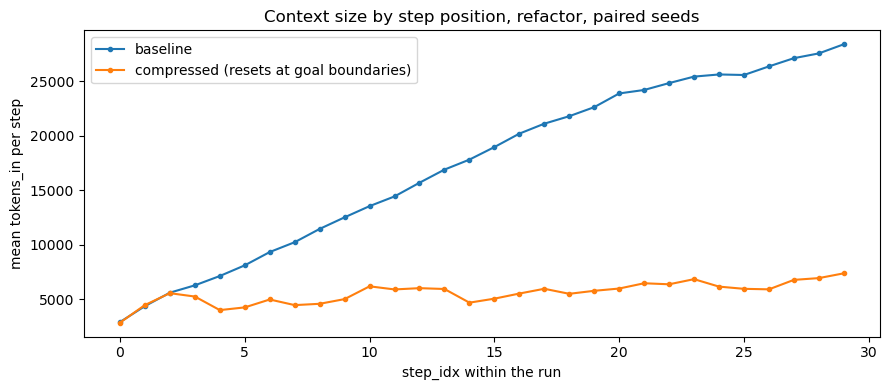

steps drawn: 0 to 29


In [6]:
def curve(arm):
    by = {}
    for s in seeds:
        for st in arm[s]["steps"]:
            by.setdefault(st["step_idx"], []).append(st["tokens_in"])
    return by

cb, cc = curve(base), curve(comp)
idx = [i for i in sorted(set(cb) & set(cc)) if len(cb[i]) >= 3 and len(cc[i]) >= 3]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(idx, [mean(cb[i]) for i in idx], marker=".", label="baseline")
ax.plot(idx, [mean(cc[i]) for i in idx], marker=".", label="compressed (resets at goal boundaries)")
ax.set_xlabel("step_idx within the run")
ax.set_ylabel("mean tokens_in per step")
ax.set_title("Context size by step position, refactor, paired seeds")
ax.legend()
fig.tight_layout()
plt.show()
print("steps drawn:", idx[0] if idx else "-", "to", idx[-1] if idx else "-")

## 5. Verdict

In [7]:
if not seeds:
    print("NO DATA: no seed ran without error in both arms.")
elif c_ok < b_ok:
    print(f"BROKE SUCCESS: compressed {c_ok}/{len(seeds)} vs baseline {b_ok}/{len(seeds)} "
          f"(tokens {change:+.1%}, which does not count)")
elif c_tok < b_tok:
    print(f"NET WIN: {-change:.1%} fewer tokens at equal/better success "
          f"({c_ok} vs {b_ok} of {len(seeds)}; summary calls included)")
else:
    print(f"NO SAVING: compressed uses {change:+.1%} tokens at {c_ok} vs {b_ok} successes")

BROKE SUCCESS: compressed 18/20 vs baseline 20/20 (tokens -54.2%, which does not count)


In [8]:
%run diagnose.py

compressed batch batch20261013_171827: 20 runs, 2 not globally OK

1. FAILED RUNS
   seed 1009  end_reason=no_tool_call  n_steps=25  runs\refactor_batch20261013_171827_run09_seed1009.json
   seed 1014  end_reason=no_tool_call  n_steps=21  runs\refactor_batch20261013_171827_run14_seed1014.json

SEED 1009   (end_reason=no_tool_call, 25 steps)

2. GOAL BOUNDARIES AND INJECTED SUMMARIES (verbatim)
   goal 0 (Establish a baseline by reading the existing code and running the current tests)
      compressed before step 5; summary:
      GOAL 0 (baseline): Read inventory.py and test_inventory.py, ran pytest (4 passed), and saved CLI reference JSON to %TEMP%\inventory_ref.json; no files changed in the working module. Contracts: Item(sku,name,qty,unit_cost) dataclass; parse_inventory(text)->list[Item] with "line N:" errors; item_value rounds to 2 dp; summarize keys item_count/total_units/total_value/low_stock; LOW_STOCK_THRESHOLD=5; main(argv) takes exactly 2 args, else usage to stderr and retur

## 6. Anti-termination fix: re-run the 3 no_tool_call seeds

Compressed mode now ends the injected block with an explicit `STATUS: NOT COMPLETE ... call a tool now` footer, and any run that still ends with `no_tool_call` stores its final reply as `final_no_tool_reply`. Seeds 1009, 1012, 1014, one run each. n=3: this checks whether the failure mode reproduces, it cannot establish a rate.

In [ ]:
# OPTIONAL: run the 3 seeds (calls the API, costs money). Flip to True once, run, flip back.
# Same as: py -3.12 batch.py --tasks refactor --seeds 1009 1012 1014 --compress --summary batch_refactor_compressed_fix.json
RUN_FIX = False

if RUN_FIX:
    import batch, harness
    batch.run_batch(batch.load_tasks(["refactor"]), harness.AnthropicAgent(), seeds=[1009, 1012, 1014],
                    summary_path="batch_refactor_compressed_fix.json", compress_at_boundaries=True)

In [1]:
import json
from pathlib import Path

FIX = Path("batch_refactor_compressed_fix.json")
if not FIX.exists():
    raise SystemExit("batch_refactor_compressed_fix.json not found: run the cell above first.")
S_fix = json.load(open(FIX, encoding="utf-8"))
fix_runs = sorted((r for r in S_fix["runs"] if r["task_id"] == "refactor"), key=lambda r: r["seed"])
if not S_fix.get("complete", True):
    print(f"WARNING: batch incomplete: {S_fix.get('stopped_early', '')[:200]}\n")

for r in fix_runs:
    print(f"seed {r['seed']}: end_reason={r['end_reason']}  global_ok={r['global_ok']}  steps={r['n_steps']}")
    if r["end_reason"] == "error":
        print(f"   ERROR: {(r.get('error') or '').strip().splitlines()[-1][:200]}")
    if r["end_reason"] == "no_tool_call":
        print("   final_no_tool_reply (verbatim):")
        print("   " + (r.get("final_no_tool_reply") or "(missing: was this run made before the logging fix?)")
              .replace("\n", "\n   "))

n = len(fix_runs)
ntc = sum(r["end_reason"] == "no_tool_call" for r in fix_runs)
ok = sum(r["global_ok"] is True for r in fix_runs)
err = sum(r["end_reason"] == "error" for r in fix_runs)
print()
if err:
    print(f"NOTE: {err}/{n} runs errored (no data); the verdict below counts them as neither.")
if ntc == 0:
    print(f"FIX WORKED: 0/{n} no_tool_call, {ok}/{n} global_ok")
else:
    print(f"STILL TERMINATING: {ntc}/{n} no_tool_call — see replies above")

seed 1009: end_reason=plan_complete  global_ok=True  steps=30
seed 1012: end_reason=no_tool_call  global_ok=False  steps=9
   final_no_tool_reply (verbatim):
   Substep 2.0 is done: `normalize_category(raw)` is in `inventory.py` and returns "general" for `None` or blank input, otherwise the stripped, lower-cased value. I haven't run the tests yet, and it isn't wired into `parse_inventory` yet; that's substep 2.1.
seed 1014: end_reason=plan_complete  global_ok=True  steps=28

STILL TERMINATING: 1/3 no_tool_call — see replies above
